In [1]:
import pandas as pd
import numpy as np
import json
import ast
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

In [2]:
# Chemin vers les données brutes
DATA_PATH = Path("../data/raw")

file_p1 = DATA_PATH / "Ligue 1 2025_2026 AS Monaco p1.csv"
file_p2 = DATA_PATH / "Ligue 1 2025_2026 AS Monaco p2.csv"

# Chargement des CSV
df_p1 = pd.read_csv(file_p1, sep=None, engine="python")
df_p2 = pd.read_csv(file_p2, sep=None, engine="python")

print("Partie 1 :", df_p1.shape)
print("Partie 2 :", df_p2.shape)

Partie 1 : (80338, 248)
Partie 2 : (55994, 248)


In [4]:
# Premier événement de la partie 1
event = df_p1.iloc[0].to_dict()

print("Clés disponibles sur le premier événement :")

for key in event.keys():
    print("-", key)

Clés disponibles sur le premier événement :
- id
- index
- match_id
- period
- timestamp
- minute
- second
- event_type_id
- event_type_name
- possession
- possession_team_id
- possession_team_name
- play_pattern_id
- play_pattern_name
- team_id
- team_name
- player_id
- player_name
- player_position_id
- player_position_name
- location_x
- location_y
- end_location_x
- end_location_y
- end_location_z
- impact_height
- duration
- under_pressure
- counterpress
- substituted_player_id
- substituted_player_name
- pass_recipient_id
- pass_recipient_name
- pass_length
- pass_angle
- pass_height_id
- pass_height_name
- pass_cross
- pass_cut_back
- pass_switch
- assisted_shot_id
- key_pass_id
- follows_dribble
- one_on_one
- open_goal
- statsbomb_xg
- off_camera
- out
- obv_for_after
- obv_for_before
- obv_for_net
- obv_against_after
- obv_against_before
- obv_against_net
- obv_total_net
- outcome_id
- outcome_name
- type_id
- type_name
- card_id
- card_name
- body_part_id
- body_part_name
- 

In [5]:
print("Nombre de champs :", len(df_p1.columns))
print("\nListe des colonnes :")
print(df_p1.columns.tolist())

Nombre de champs : 248

Liste des colonnes :
['id', 'index', 'match_id', 'period', 'timestamp', 'minute', 'second', 'event_type_id', 'event_type_name', 'possession', 'possession_team_id', 'possession_team_name', 'play_pattern_id', 'play_pattern_name', 'team_id', 'team_name', 'player_id', 'player_name', 'player_position_id', 'player_position_name', 'location_x', 'location_y', 'end_location_x', 'end_location_y', 'end_location_z', 'impact_height', 'duration', 'under_pressure', 'counterpress', 'substituted_player_id', 'substituted_player_name', 'pass_recipient_id', 'pass_recipient_name', 'pass_length', 'pass_angle', 'pass_height_id', 'pass_height_name', 'pass_cross', 'pass_cut_back', 'pass_switch', 'assisted_shot_id', 'key_pass_id', 'follows_dribble', 'one_on_one', 'open_goal', 'statsbomb_xg', 'off_camera', 'out', 'obv_for_after', 'obv_for_before', 'obv_for_net', 'obv_against_after', 'obv_against_before', 'obv_against_net', 'obv_total_net', 'outcome_id', 'outcome_name', 'type_id', 'type_na

In [7]:
def parse_nested_value(value):
    if not isinstance(value, str):
        return value

    value = value.strip()

    if not value:
        return value

    try:
        return json.loads(value)
    except (json.JSONDecodeError, TypeError):
        pass

    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return value

def identify_nested_columns(df):

    dict_columns = []
    list_columns = []

    for column in df.columns:

        values = df[column].dropna().head(1000)
        parsed_values = values.map(parse_nested_value)

        if parsed_values.map(lambda x: isinstance(x, dict)).any():
            dict_columns.append(column)

        if parsed_values.map(lambda x: isinstance(x, list)).any():
            list_columns.append(column)

    return dict_columns, list_columns


dict_cols_p1, list_cols_p1 = identify_nested_columns(df_p1)
dict_cols_p2, list_cols_p2 = identify_nested_columns(df_p2)

print("Partie 1")
print("Colonnes contenant des dictionnaires :", dict_cols_p1)
print("Colonnes contenant des listes :", list_cols_p1)

print("\nPartie 2")
print("Colonnes contenant des dictionnaires :", dict_cols_p2)
print("Colonnes contenant des listes :", list_cols_p2)

Partie 1
Colonnes contenant des dictionnaires : []
Colonnes contenant des listes : []

Partie 2
Colonnes contenant des dictionnaires : []
Colonnes contenant des listes : []


In [9]:
for col in df_p1.columns:
    exemples = df_p1[col].dropna().astype(str).head(3)
    print(f"\n--- {col} ---")
    print(exemples.tolist())


--- id ---
['144b3bdf-745d-5ee1-af2e-3dc759ea47cc', 'eb98c85c-a6ae-5609-a8d6-9dc87c0b75ad', '20fa6759-a486-5c5c-a691-5f10897ca41b']

--- index ---
['1', '2', '3']

--- match_id ---
['3999407', '3999407', '3999407']

--- period ---
['1', '1', '1']

--- timestamp ---
['00:00', '00:00', '00:00:00.000']

--- minute ---
['0', '0', '0']

--- second ---
['0', '0', '0']

--- event_type_id ---
['35', '35', '18']

--- event_type_name ---
['Starting XI', 'Starting XI', 'Half Start']

--- possession ---
['1', '1', '1']

--- possession_team_id ---
['129.0', '129.0', '129.0']

--- possession_team_name ---
['AS Monaco', 'AS Monaco', 'AS Monaco']

--- play_pattern_id ---
['5', '5', '5']

--- play_pattern_name ---
['Other', 'Other', 'Other']

--- team_id ---
['129', '164', '129']

--- team_name ---
['AS Monaco', 'Le Havre', 'AS Monaco']

--- player_id ---
['134854.0', '5538.0', '5538.0']

--- player_name ---
['Mika Miles Biereth', 'Denis Lemi Zakaria Lako Lado', 'Denis Lemi Zakaria Lako Lado']

--- pl

In [10]:
for column in df_p1.columns:
    types = df_p1[column].dropna().map(type).unique()
    print(column, types)

id [<class 'str'>]
index [<class 'int'>]
match_id [<class 'int'>]
period [<class 'int'>]
timestamp [<class 'str'>]
minute [<class 'int'>]
second [<class 'int'>]
event_type_id [<class 'int'>]
event_type_name [<class 'str'>]
possession [<class 'int'>]
possession_team_id [<class 'float'>]
possession_team_name [<class 'str'>]
play_pattern_id [<class 'int'>]
play_pattern_name [<class 'str'>]
team_id [<class 'int'>]
team_name [<class 'str'>]
player_id [<class 'float'>]
player_name [<class 'str'>]
player_position_id [<class 'float'>]
player_position_name [<class 'str'>]
location_x [<class 'float'>]
location_y [<class 'float'>]
end_location_x [<class 'float'>]
end_location_y [<class 'float'>]
end_location_z [<class 'float'>]
impact_height [<class 'float'>]
duration [<class 'float'>]
under_pressure [<class 'bool'>]
counterpress [<class 'bool'>]
substituted_player_id [<class 'float'>]
substituted_player_name [<class 'str'>]
pass_recipient_id [<class 'float'>]
pass_recipient_name [<class 'str'>]


In [14]:
event_distribution = (
    df_p1["event_type_name"]
    .value_counts()
    .rename_axis("event_type")
    .reset_index(name="count")
)

display(event_distribution)

,event_type,count
0,Pass,19851
1,Ball Receipt*,17551
2,Carries,15847
3,Pressure,8664
4,Shot,7656
5,Ball Recovery,1951
6,Duel,1206
7,Block,874
8,Tactical Shift,788
9,Goal Keeper,673


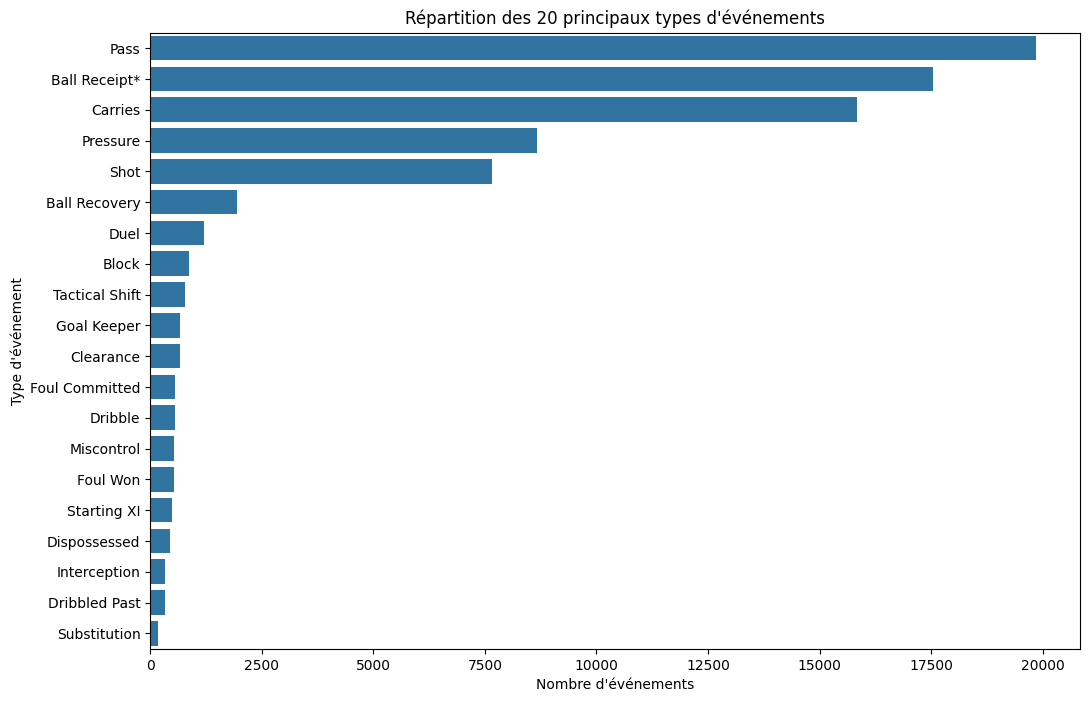

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.barplot(
    data=event_distribution.head(20),
    x="count",
    y="event_type"
)

plt.title("Répartition des 20 principaux types d'événements")
plt.xlabel("Nombre d'événements")
plt.ylabel("Type d'événement")

plt.show()